# M00 概覽 | 把模型變成一張圖：torch.export、ATen 與 fx

PT2E 量化的每一步，都是在一張「計算圖」上做事。這一章先回答三件事：為什麼需要這張圖、圖上的運算為什麼都是 ATen op、這張圖由哪些元素組成、怎麼修改它。
後面四本 notebook（M00-1～M00-4）再逐一動手看。

In [1]:
#| echo: false
import copy

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.export import export

from common.graph_utils import short
from common.models import example_inputs, get_model
from common.pt2e import MinMaxObserver, export_module, quiet
from common.viz import draw, draw_stages, table

quiet()
_ = torch.manual_seed(0)

## 為什麼需要一張圖

量化要逐個 tensor 做決定：這個 tensor 要不要存成 int8、用多大的 scale。要做這些決定，得先知道每個 tensor **由哪個運算產生、被哪些運算使用**，也就是整個模型的資料流。

但 `nn.Module` 的 `forward` 是一段任意的 Python 程式：裡面可以有迴圈、if、呼叫別的 module、呼叫函式。不實際執行，很難說出它算了什麼；執行了，也只得到數值，得不到結構。

所以第一步是把模型「抓」成一張圖：每個運算是一個 node，node 之間的邊就是 tensor 的流向。PT2E 的全名是 PyTorch 2 **Export** quantization，抓圖用的就是 `torch.export`。
之後的標註、插 observer、換成 quantize／dequantize，全都是在讀、改這張圖。

## 為什麼圖上都是 ATen op

圖做出來，最後要交給後端：XNNPACK、ONNX Runtime、各家 NPU。後端拿到圖，第一件事是逐個 node 判斷「這個運算我有沒有 kernel」。
這要求圖上的運算名稱**統一**而且**數量有限**，後端才能拿自己支援的清單來對照。

以前 fx 的抓圖方式 `torch.fx.symbolic_trace` 做不到這一點。同一個模型（conv → relu → 平均 → linear）用三種 Python 寫法，各用兩種方式抓圖：

In [2]:
#| echo: false
class FunctionalStyle(nn.Module):
    def __init__(self):
        super().__init__()
        self.w = nn.Parameter(torch.randn(8, 3, 3, 3))
        self.fc_w = nn.Parameter(torch.randn(4, 8))

    def forward(self, x):
        return F.linear(F.relu(F.conv2d(x, self.w, padding=1)).mean((2, 3)), self.fc_w)


class ModuleStyle(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Conv2d(3, 8, 3, padding=1, bias=False)
        self.act = nn.ReLU()
        self.fc = nn.Linear(8, 4, bias=False)

    def forward(self, x):
        return self.fc(self.act(self.conv(x)).mean((2, 3)))


class SequentialStyle(nn.Module):
    def __init__(self):
        super().__init__()
        self.body = nn.Sequential(nn.Conv2d(3, 8, 3, padding=1, bias=False), nn.ReLU())
        self.fc = nn.Linear(8, 4, bias=False)

    def forward(self, x):
        return self.fc(self.body(x).mean((2, 3)))


def fx_ops(gm):
    out = []
    for n in gm.graph.nodes:
        if n.op == "call_module":
            out.append(f"module {type(gm.get_submodule(n.target)).__name__}({n.target})")
        elif n.op == "call_function":
            out.append(f"function {n.target.__name__}")
        elif n.op == "call_method":
            out.append(f"method {n.target}")
    return out


styles = [("F.conv2d、F.relu…", FunctionalStyle), ("nn.Conv2d、nn.ReLU…", ModuleStyle), ("nn.Sequential", SequentialStyle)]
ex_small = (torch.randn(2, 3, 8, 8),)
rows, export_lists = [], []
for label, cls in styles:
    e = [n.target for n in export(cls().eval(), ex_small).module().graph.nodes if n.op == "call_function"]
    export_lists.append(e)
    rows.append([label, " → ".join(fx_ops(torch.fx.symbolic_trace(cls()))), " → ".join(short(t) for t in e)])
assert all(e == export_lists[0] for e in export_lists)
table(rows, ["寫法", "torch.fx.symbolic_trace 的 node", "torch.export 的 node"])

寫法,torch.fx.symbolic_trace 的 node,torch.export 的 node
F.conv2d、F.relu…,function conv2d → function relu → method mean → function linear,conv2d → relu → mean → linear
nn.Conv2d、nn.ReLU…,module Conv2d(conv) → module ReLU(act) → method mean → module Linear(fc),conv2d → relu → mean → linear
nn.Sequential,module Conv2d(body.0) → module ReLU(body.1) → method mean → module Linear(fc),conv2d → relu → mean → linear


- `symbolic_trace` 的圖跟著寫法走：`nn.Conv2d` 留成一個 module（連它在模型裡的路徑 `body.0` 都在），`F.conv2d` 是一個 Python 函式，`.mean()` 是一個 method。
  同一個 conv 有好幾種長相，後端得認得每一種 `nn.Module` 類別和每一種 Python 寫法，才判斷得出自己支不支援。
- `torch.export` 的圖不管怎麼寫，都是同一串 `aten.*` op，module 的階層也被攤平了。

**ATen** 是 PyTorch 的核心 tensor 函式庫，PyTorch 的運算最後都落到它定義的 op 上。`torch.export` 的官方文件寫明：export 出來的圖只含 ATen op（和使用者自訂的 op），而且是攤平、沒有 Python 語意的
（[torch.export](https://docs.pytorch.org/docs/main/user_guide/torch_compiler/export.html)）。
ATen 裡還挑出一組約 180 個 op 的 **Core ATen**，文件說它就是設計來當作與後端對接的 IR（[IRs](https://docs.pytorch.org/docs/main/user_guide/torch_compiler/torch.compiler_ir.html)）。
後端只要實作這組 op，就能接住任何 export 出來的模型。

ATen 可以拆到不同的深度，export 文件列了三個層級：

| 層級 | 怎麼得到 | op 數量（文件） | 用途 |
|---|---|---|---|
| export 預設 | `torch.export.export()` | 約 3000 | PT2E 在這一層標註 |
| 拆掉原地修改 | `ep.run_decompositions({})` | 約 2000 | 推論部署 |
| Core ATen | `ep.run_decompositions()` | 約 180 | 想把要實作的 op 降到最少的後端 |

PT2E 在最上面那層標註：`conv2d`、`batch_norm` 都還是一整個 op，「conv → bn → relu」這種樣式最好認。要拆到多深，由後端決定（M00-3）。

另外，`torch.export` 取代 `symbolic_trace` 還有一個不同的理由：它用 TorchDynamo 在 Python bytecode 層追蹤，能抓到 symbolic_trace 追不動的程式（例如依 tensor shape 的判斷）。
這是「抓得到圖」的問題，和「圖上用什麼詞彙」是兩件事。

## 先看一個例子

本專案的 `ConvBnReLU`：

```python
class ConvBnReLU(nn.Module):
    def __init__(self, cin=3, cout=8, bias=False):
        super().__init__()
        self.conv = nn.Conv2d(cin, cout, 3, padding=1, bias=bias)
        self.bn = nn.BatchNorm2d(cout)
        self.relu = nn.ReLU()

    def forward(self, x):
        return self.relu(self.bn(self.conv(x)))
```

`torch.export.export(model.eval(), (x,)).module()` 之後的圖：

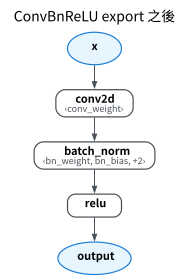

In [3]:
#| echo: false
model = get_model("conv_bn_relu").eval()
ex = example_inputs()
ep = export(model, ex)
gm = ep.module()
draw(gm, title="ConvBnReLU export 之後")

三個 module 變成三個運算 node：`conv2d`、`batch_norm`、`relu`。weight、BN 的參數與 running stats 寫在使用它們的 node 底下的 `‹…›` 裡；它們在圖上也是 node（`get_attr`），只是沒有另外畫。
輸入 `x` 和輸出 `output` 是圖的兩端。

## 定義

### ExportedProgram 與 GraphModule

`torch.export.export(model, args)` 回傳 **ExportedProgram**（`ep`），裡面有三樣東西：

- `ep.graph`：圖本身。參數、buffer、使用者輸入**全都是圖的輸入**（placeholder）。
- `ep.graph_signature`：說明每個 placeholder 是參數、buffer 還是使用者輸入，以及對應原模型的哪個欄位。
- `ep.state_dict`：參數和 buffer 的值。

`ep.module()` 依 signature 把 state_dict 綁回去，回傳一個可以直接呼叫的 **GraphModule**：參數變成從自己身上讀屬性的 `get_attr` node，只剩 `x` 是 placeholder。
PT2E 的 `prepare_pt2e` 吃的是這個 GraphModule（M00-1 A 段）。

### Node

GraphModule 裡的 `gm.graph` 是一串 **node**，依執行順序排列。export 出來的圖只會有五種 node（`node.op`）：

| `node.op` | 意思 | 例子 |
|---|---|---|
| `placeholder` | 圖的輸入 | `x` |
| `get_attr` | 讀 GraphModule 上的參數或 buffer | `conv_weight` |
| `call_function` | 呼叫一個函式，在 export 的圖裡就是 ATen op | `conv2d` |
| `call_module` | 呼叫 GraphModule 上的子模組 | `_guards_fn`（輸入檢查）；之後 prepare 插的 observer |
| `output` | 圖的輸出 | `output` |

每個 node 還有幾個常用屬性：`target`（呼叫誰）、`args`（吃哪些 node 或常數）、`users`（被誰使用）、`meta`（export 時收集的資訊，例如輸出的 shape）。拿圖上的 `conv2d` 看：

In [4]:
conv = next(n for n in gm.graph.nodes if n.name == "conv2d")
print(f"op     = {conv.op}")
print(f"target = {conv.target}")
print(f"args   = {conv.args}")
print(f"users  = {list(conv.users)}")
print(f"meta['val'] 的 shape = {list(conv.meta['val'].shape)}")
assert conv.op == "call_function" and conv.target is torch.ops.aten.conv2d.default

op     = call_function
target = aten.conv2d.default
args   = (x, conv_weight, None, [1, 1], [1, 1])
users  = [batch_norm]
meta['val'] 的 shape = [2, 8, 16, 16]


`args` 裡的 `x` 和 `conv_weight` 是 node（邊就是這樣來的）；`None` 是 bias（這個 conv 沒有 bias），`[1, 1]` 是 stride 和 padding，這些常數直接寫在參數裡。
`users` 的反方向就是 `args`：`batch_norm` 吃 `conv2d`，所以 `conv2d.users` 裡有 `batch_norm`。量化的標註之後也會寫進 `meta`（M01-2）。

### ATen op 的名字

`torch.ops.aten.conv2d.default` 分三段：`aten` 是名稱空間，`conv2d` 是 op，`default` 是 overload（同一個 op 依參數型別有不同版本，例如 `add.Tensor`、`add.Scalar`）。
圖上的 `node.target` 就是這個物件，quantizer 用 `node.target == torch.ops.aten.conv2d.default` 來找 conv（M00-1 B 段）。

### 模式在 export 時就寫死

呼叫 `model.eval()` 或 `model.train()` 之後再 export，得到的圖不同：`batch_norm` 的 `training` 參數會寫成 False 或 True，train 模式還多一個更新 `num_batches_tracked` 的 node。
export 之後的 GraphModule 不能再用 `.train()`／`.eval()` 切換。PTQ 用 eval 模式 export，QAT 用 train 模式（M00-2）。

### Decomposition

把大 op 拆成小 op 叫 **decomposition**，用 `ep.run_decompositions(表)`。例如 `batch_norm` 會拆成 `_native_batch_norm_legit_no_training` + `getitem`；用 Core ATen 的表，`conv2d` 也會變成 `convolution`（M00-3）。

## 改圖的四個動作

PT2E 的 `prepare_pt2e`、`convert_pt2e` 都在改圖。改圖只有四個基本動作：

| 動作 | API | 例子 |
|---|---|---|
| 插入 | `graph.inserting_after(n)` 裡呼叫 `graph.call_module` 或 `graph.call_function` | 在 relu 後面建一個 observer |
| 改接 | `n.replace_all_uses_with(new, delete_user_cb=...)` | 原本吃 relu 的 node 改吃 observer |
| 取代 | 插入新的 → 改接 → `graph.erase_node(舊的)` | convert 把 observer 換成 q/dq |
| 清理 | `graph.eliminate_dead_code()`、`graph.lint()` | 刪掉沒人用的 node、檢查結構 |

改完之後要 `gm.recompile()`，GraphModule 的 forward 才會依新的圖重新產生。
下圖用這幾個動作，手動在 conv → relu 的 relu 後面插一個 `MinMaxObserver`，這正是 `prepare_pt2e` 做的事：

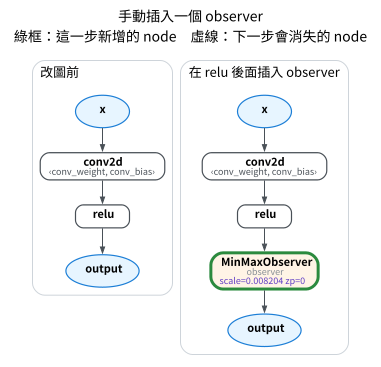

In [5]:
#| echo: false
gm_before = export_module(get_model("conv_relu").eval(), example_inputs(4))
gm_after = copy.deepcopy(gm_before)
relu = next(n for n in gm_after.graph.nodes if n.name == "relu")
gm_after.add_submodule("observer", MinMaxObserver())
with gm_after.graph.inserting_after(relu):
    obs = gm_after.graph.call_module("observer", (relu,))
relu.replace_all_uses_with(obs, delete_user_cb=lambda user: user is not obs)
gm_after.recompile()
with torch.no_grad():
    x = example_inputs(4)[0]
    assert torch.equal(gm_before(x), gm_after(x))  # observer 只觀察，不改數值
draw_stages([(gm_before, "改圖前"), (gm_after, "在 relu 後面插入 observer")], title="手動插入一個 observer")

observer（綠框）插在 relu 和 output 之間，原本吃 relu 的 output 改吃 observer。observer 原樣傳回輸入，所以改圖前後的輸出完全相同。
每個動作的細節與常見的坑（例如少了 `delete_user_cb` 會讓新 node 吃到自己）在 M00-4。

## 小結與本章地圖

- 量化要知道每個 tensor 的來源與去向，所以先用 `torch.export` 把模型抓成一張圖。
- 圖上只有 ATen op：不管 Python 怎麼寫，後端與 quantizer 只要認得這組 op。
- 圖由 node 組成；node 的 `op`、`target`、`args`、`users`、`meta` 是之後每一章都會用到的詞彙。
- 改圖就是插入、改接、取代、清理，最後 `recompile`；prepare 和 convert 都是這幾個動作的組合。

| notebook | 回答的問題 |
|---|---|
| [M00-1 export 出來的圖](01_export_and_inspect.ipynb) | ExportedProgram 與 GraphModule 差在哪、node 上有什麼、ATen 是什麼、不同寫法為什麼變成同一串 op |
| [M00-2 eval 與 train](02_eval_vs_train.ipynb) | 模式怎麼寫進圖裡、為什麼 export 之後不能切換 |
| [M00-3 Decomposition](03_decomposition.ipynb) | 大 op 怎麼拆、為什麼 PT2E 在拆之前標註 |
| [M00-4 改圖](04_fx_graph_editing.ipynb) | 六個改圖步驟，以及每一步的坑 |

這一章刻意跳過的：動態 shape（`torch.export.Dim`，本專案的 `export_module()` 只把 batch 設成動態）、控制流（`torch.cond`）、自訂 op、ExportedProgram 的存檔與載入。

## 參考資料

- [torch.export 官方文件](https://docs.pytorch.org/docs/main/user_guide/torch_compiler/export.html)：ExportedProgram、graph signature、IR 的三個層級、與 `symbolic_trace` 的比較
- [IRs：Core ATen IR 與 Prims IR](https://docs.pytorch.org/docs/main/user_guide/torch_compiler/torch.compiler_ir.html)：Core ATen 的 op 清單與定位
- [torch.fx 官方文件](https://docs.pytorch.org/docs/stable/fx.html)：Graph、Node、GraphModule 的 API
- [ATen 的 C++ 文件](https://docs.pytorch.org/cppdocs/)；所有 ATen op 的定義在 [`native_functions.yaml`](https://github.com/pytorch/pytorch/blob/main/aten/src/ATen/native/native_functions.yaml)
- [PyTorch FX 的 Graph／Node 一些基礎概念](https://bobondemon.github.io/2025/07/29/%E7%AD%86%E8%A8%98-PyTorch-FX-%E7%9A%84-Graph-Node-%E4%B8%80%E4%BA%9B%E5%9F%BA%E7%A4%8E%E6%A6%82%E5%BF%B5/)：node 的雙向鏈結、`replace_all_uses_with`、`erase_node` 怎麼維護圖的一致